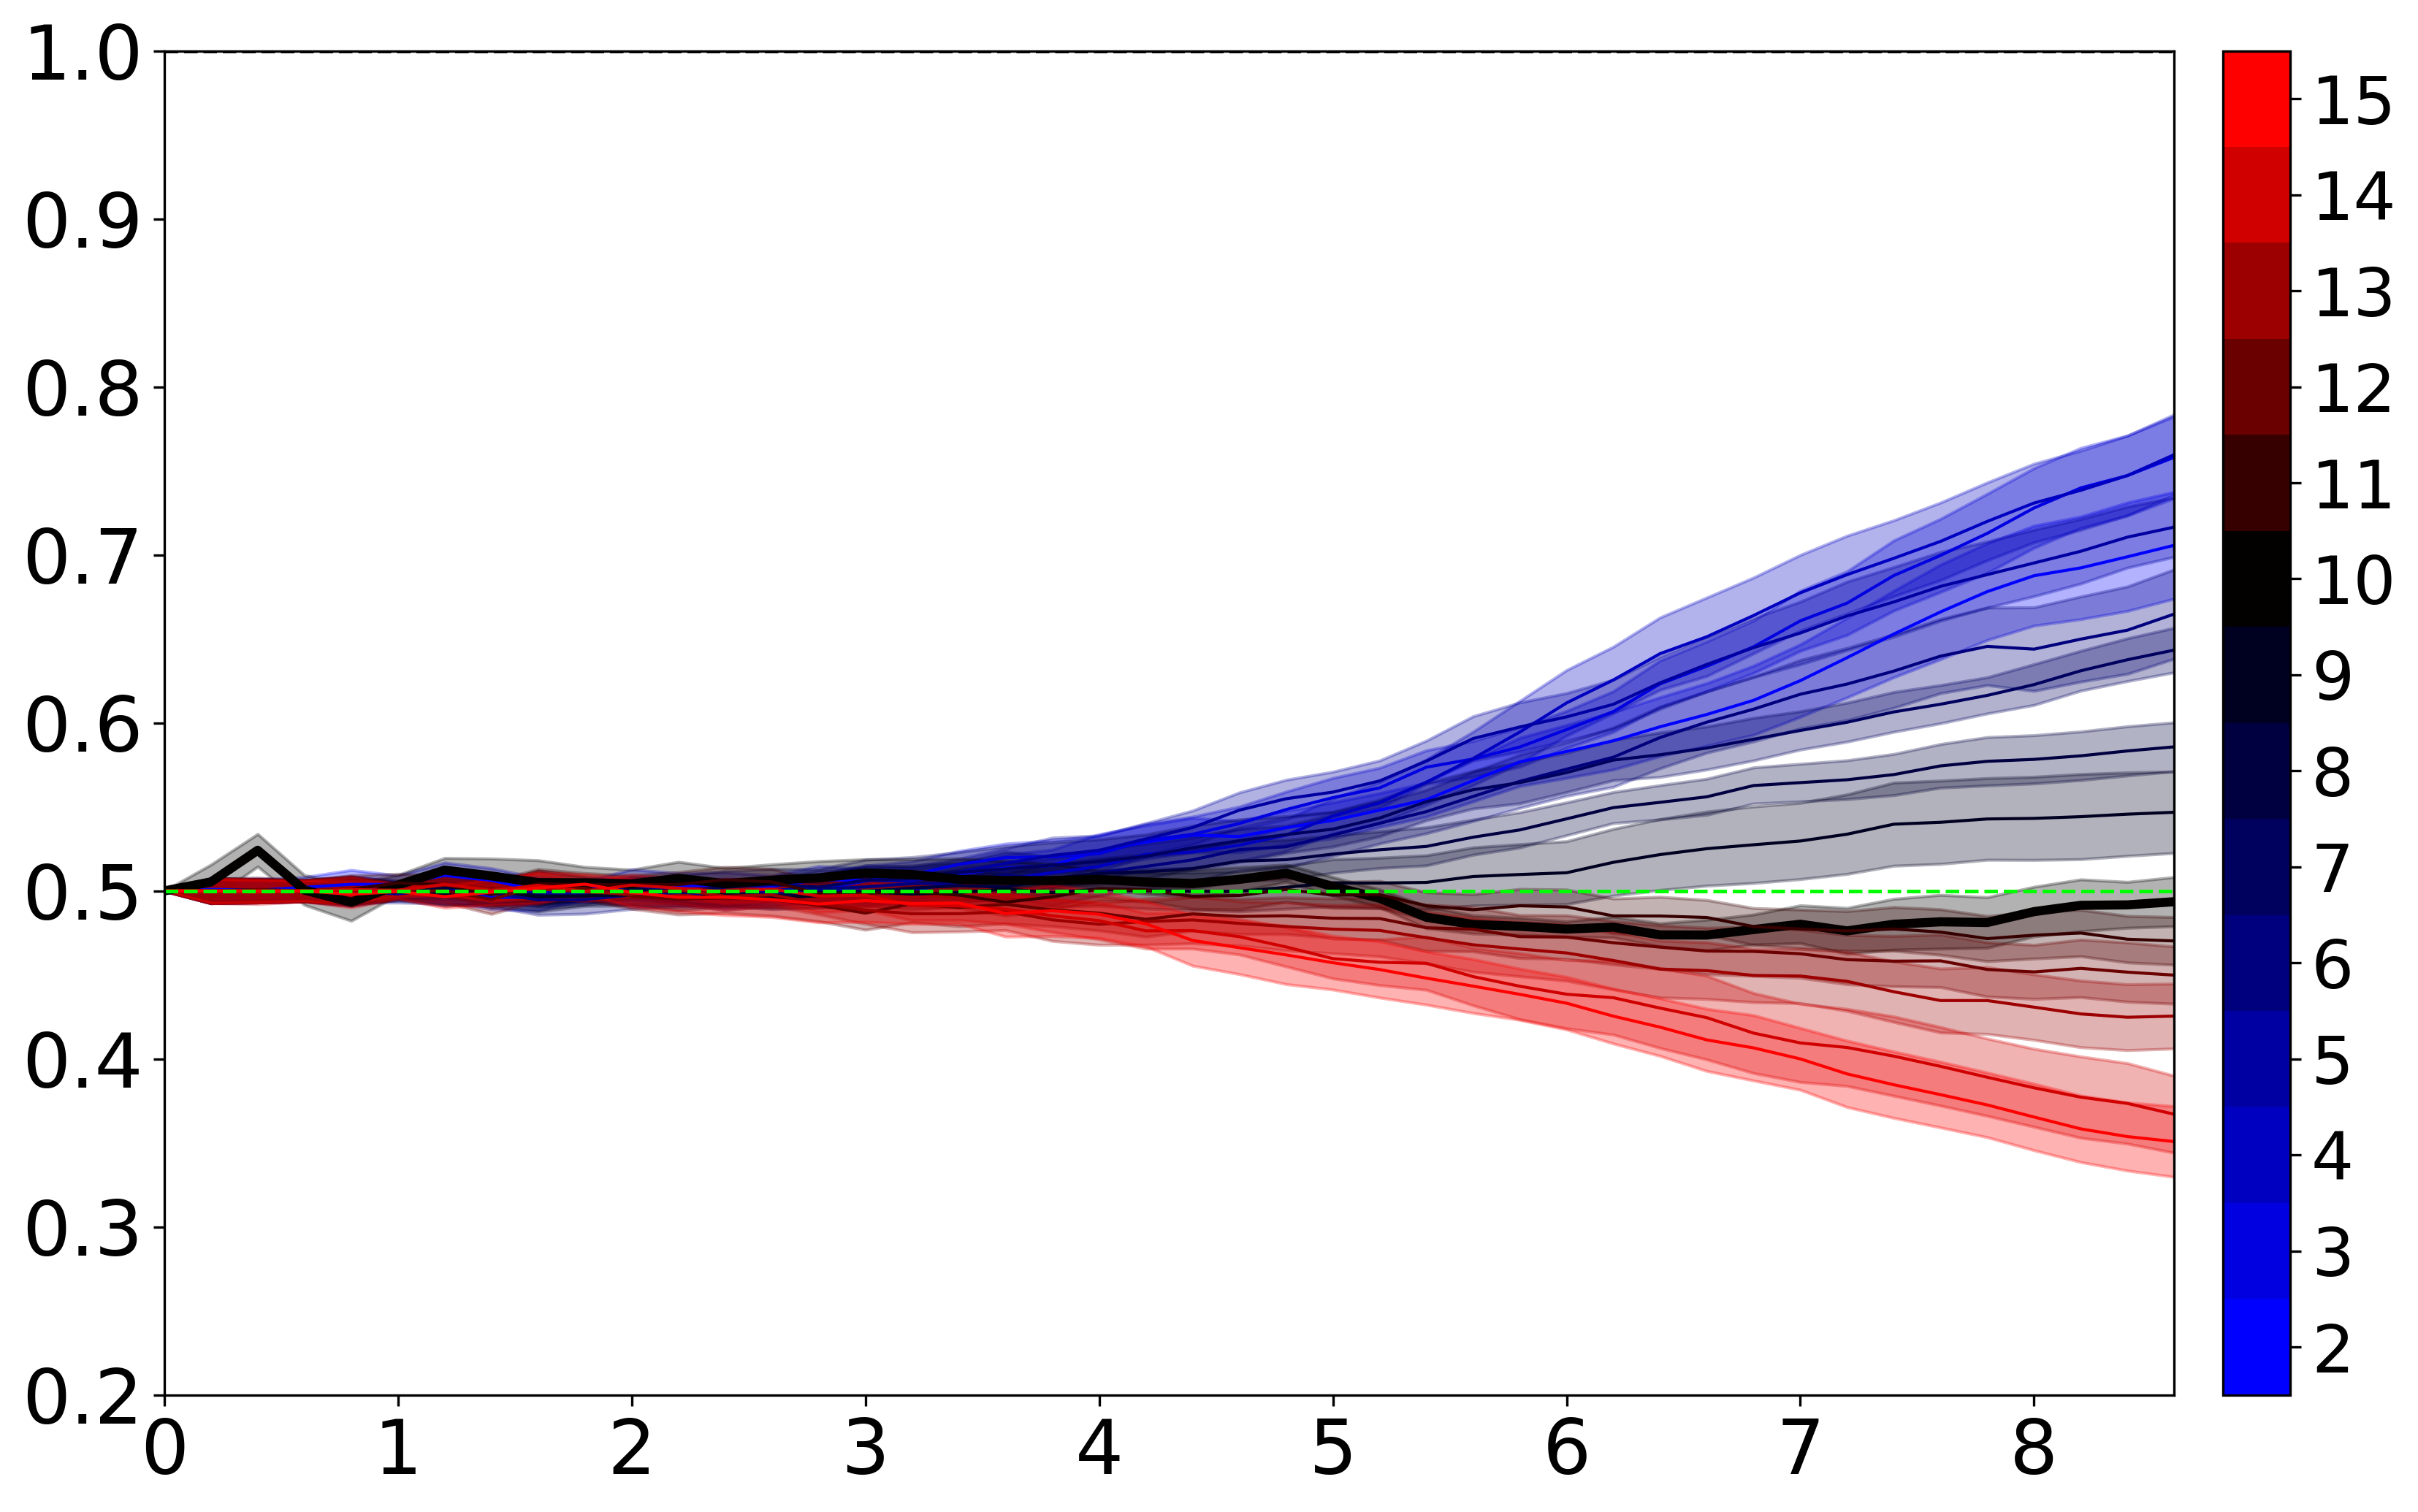

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.colors as mcolors

df = pd.read_csv("/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/investigations/MAR26_all_aspects_periphery_fractions_w=20d.csv")


df = df[(df['Aspect_Ratio_1'] == 10) | (df['Aspect_Ratio_2'] == 10)]

#Aspect_Ratio_1 is always 10 
mask = df['Aspect_Ratio_2'] == 10
df.loc[mask, 'Avg_Fraction_Asp1'] = 1 - df.loc[mask, 'Avg_Fraction_Asp1']
df.loc[mask, ['Aspect_Ratio_1', 'Aspect_Ratio_2']] = df.loc[mask, ['Aspect_Ratio_2', 'Aspect_Ratio_1']].values

grouped = df.groupby(['Time', 'Aspect_Ratio_2']).agg(
    Avg_Fraction_Asp1=('Avg_Fraction_Asp1', 'mean'),
    SEM_Avg_Fraction_Asp1=('SEM_Avg_Fraction_Asp1', lambda x: np.sqrt(np.sum(x**2)) / len(x))
).reset_index()

colors = ['blue', 'black', 'red']
cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", colors, N=100)
norm = mcolors.TwoSlopeNorm(vmin=2, vcenter=10, vmax=15)

fig, ax = plt.subplots(figsize=(12, 7), dpi=300)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

for asp2, data_subset in grouped.groupby('Aspect_Ratio_2'):
    times = [t / 4 for t in data_subset['Time']]
    avg_output1 = data_subset['Avg_Fraction_Asp1']
    sem_output1 = data_subset['SEM_Avg_Fraction_Asp1']

    color = cmap(norm(asp2))
    linewidth = 3 if asp2 == 10 else 1

    ax.fill_between(times, avg_output1 - sem_output1, avg_output1 + sem_output1, color=color, alpha=0.3)
    ax.plot(times, avg_output1, '-', color=color, linewidth=linewidth)

ax.axhline(1, color='black', linestyle='--', linewidth=1.2)
ax.axhline(0.5, color='lime', linestyle='--', linewidth=1.2)

ax.tick_params(axis='both', labelsize=25)
ax.set_ylim(0.2, 1.0)
ax.set_xlim(0, 8.6)
ax.set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

boundaries = [i - 0.5 for i in range(2, 17)]
cbar = plt.colorbar(sm, ax=ax, orientation='vertical', pad=0.02, boundaries=boundaries)
cbar.set_ticks(range(2, 16))
cbar.ax.tick_params(labelsize=22)
cbar.set_ticklabels([str(i) for i in range(2, 16)])

plt.tight_layout()
plt.savefig("MAR26_ar10_periphery_timeseries.png", dpi=300)
plt.show()

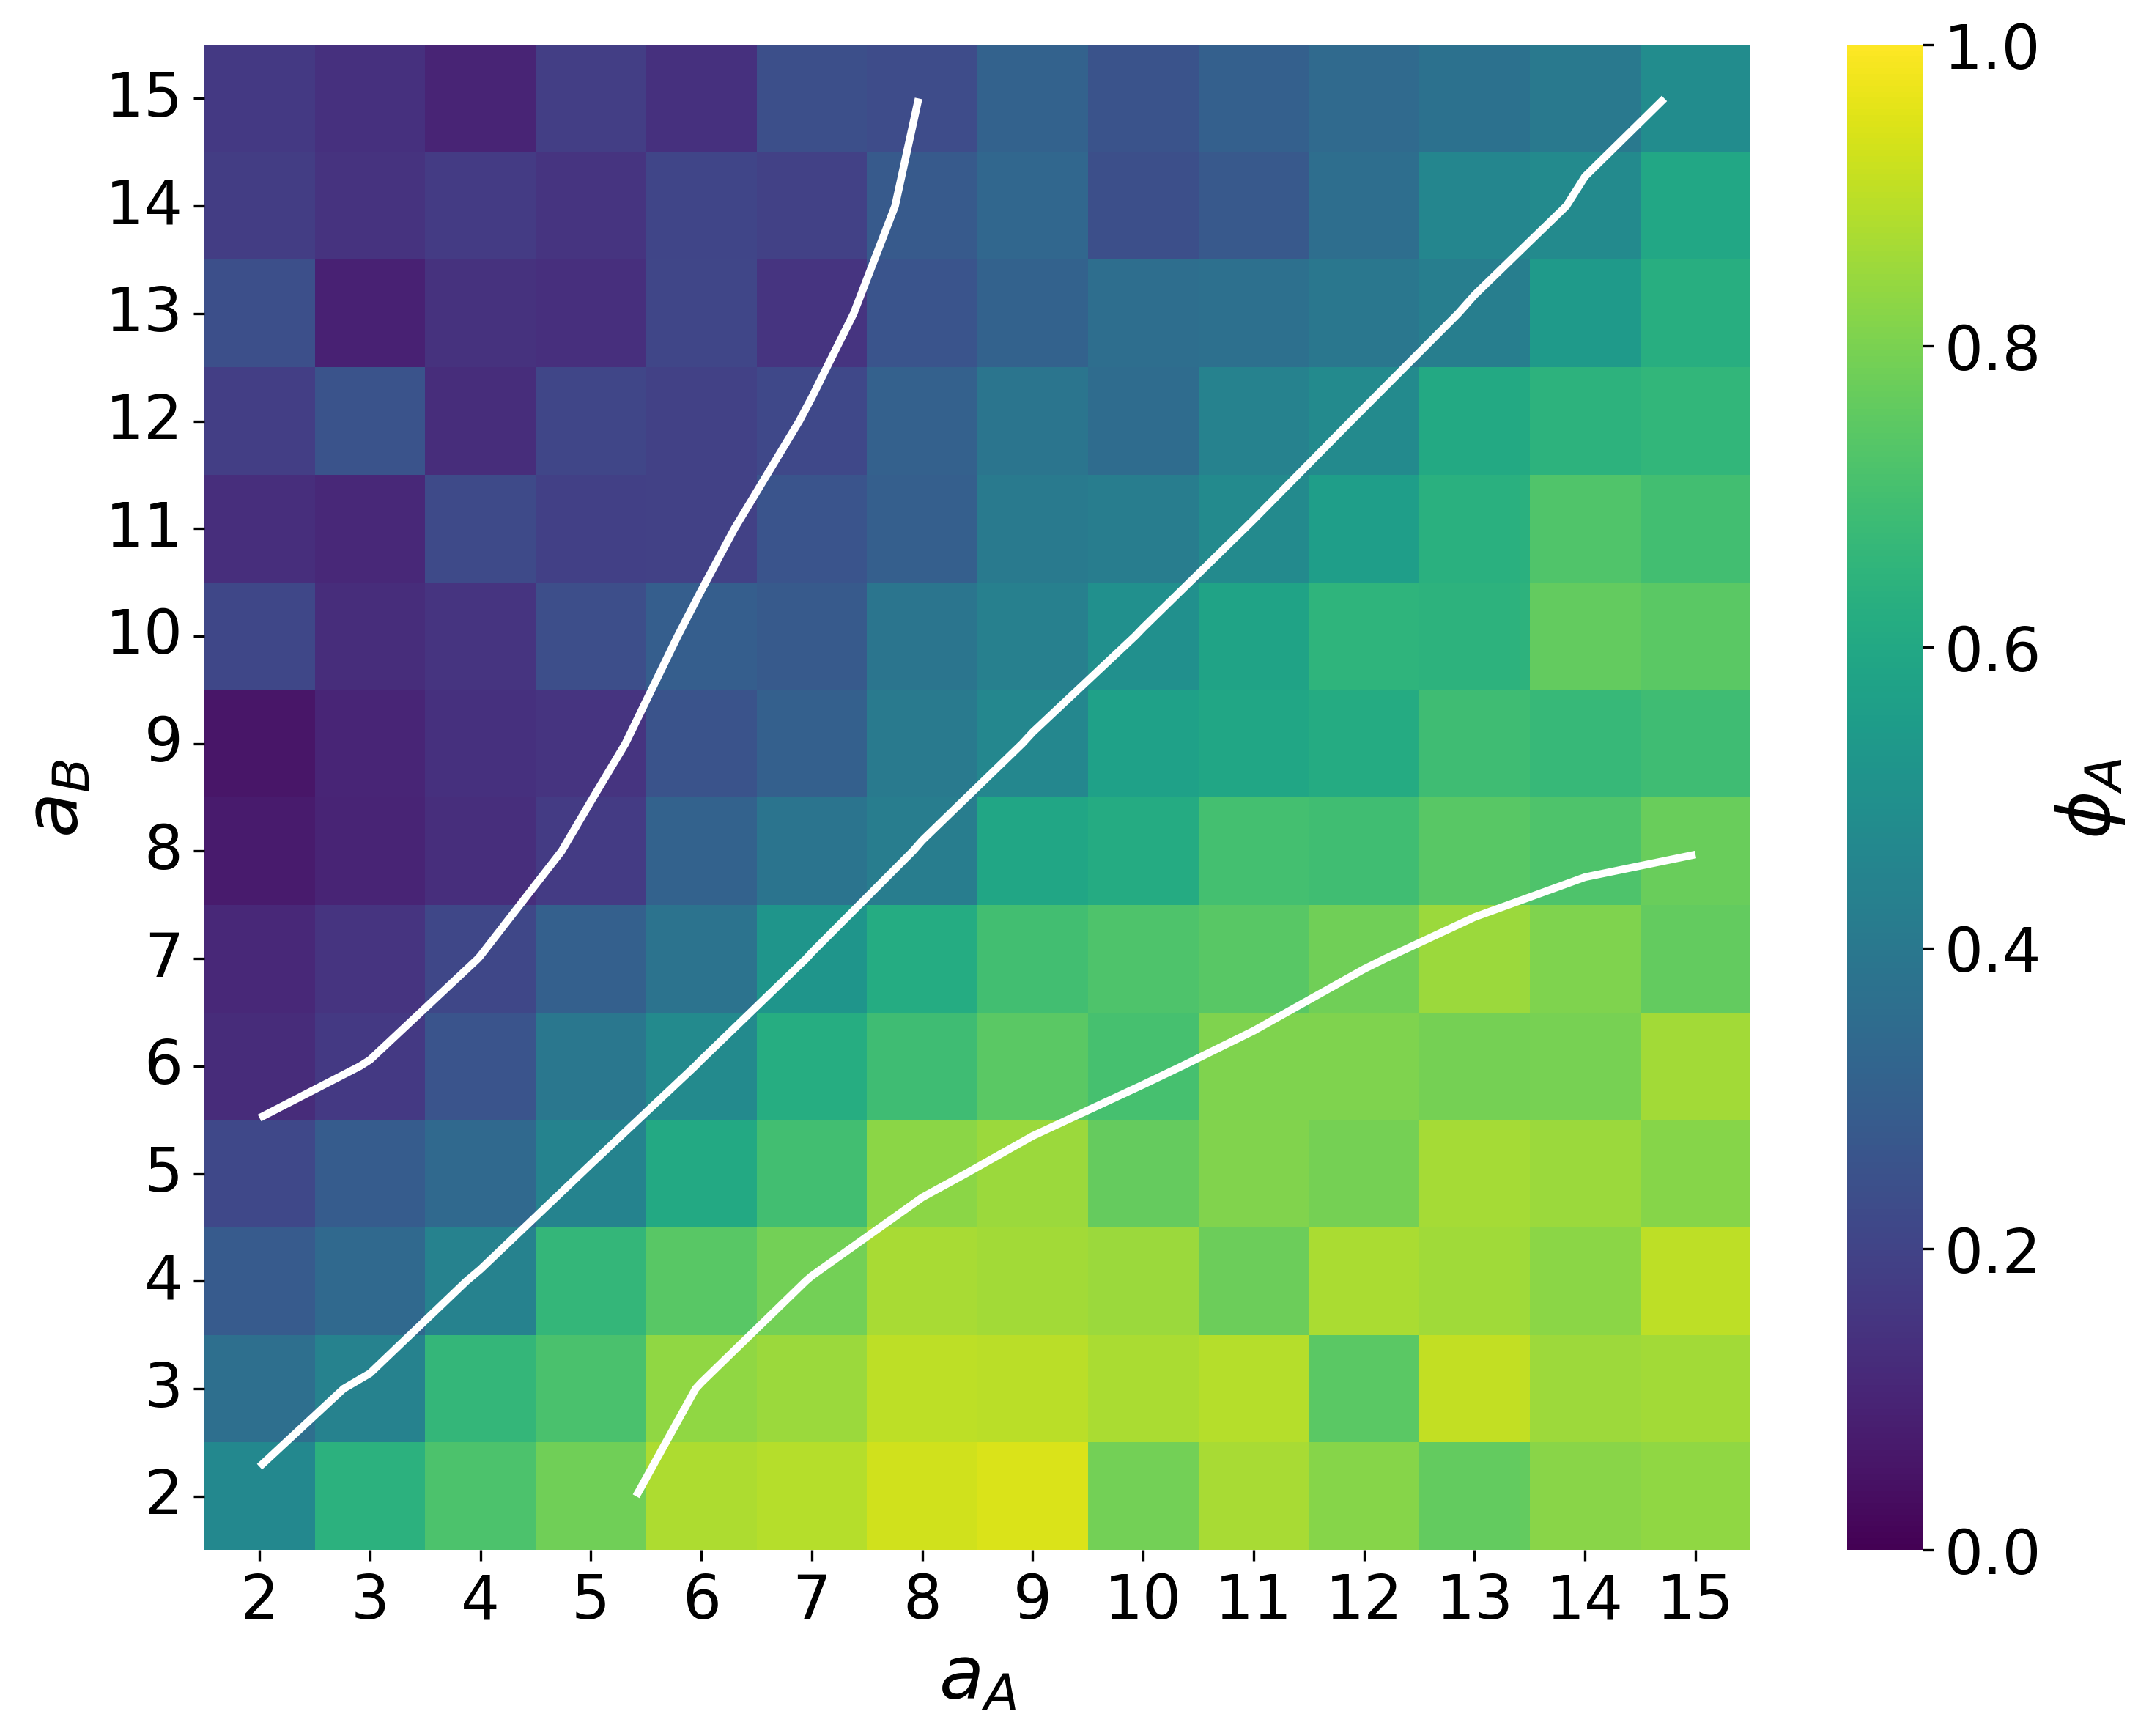

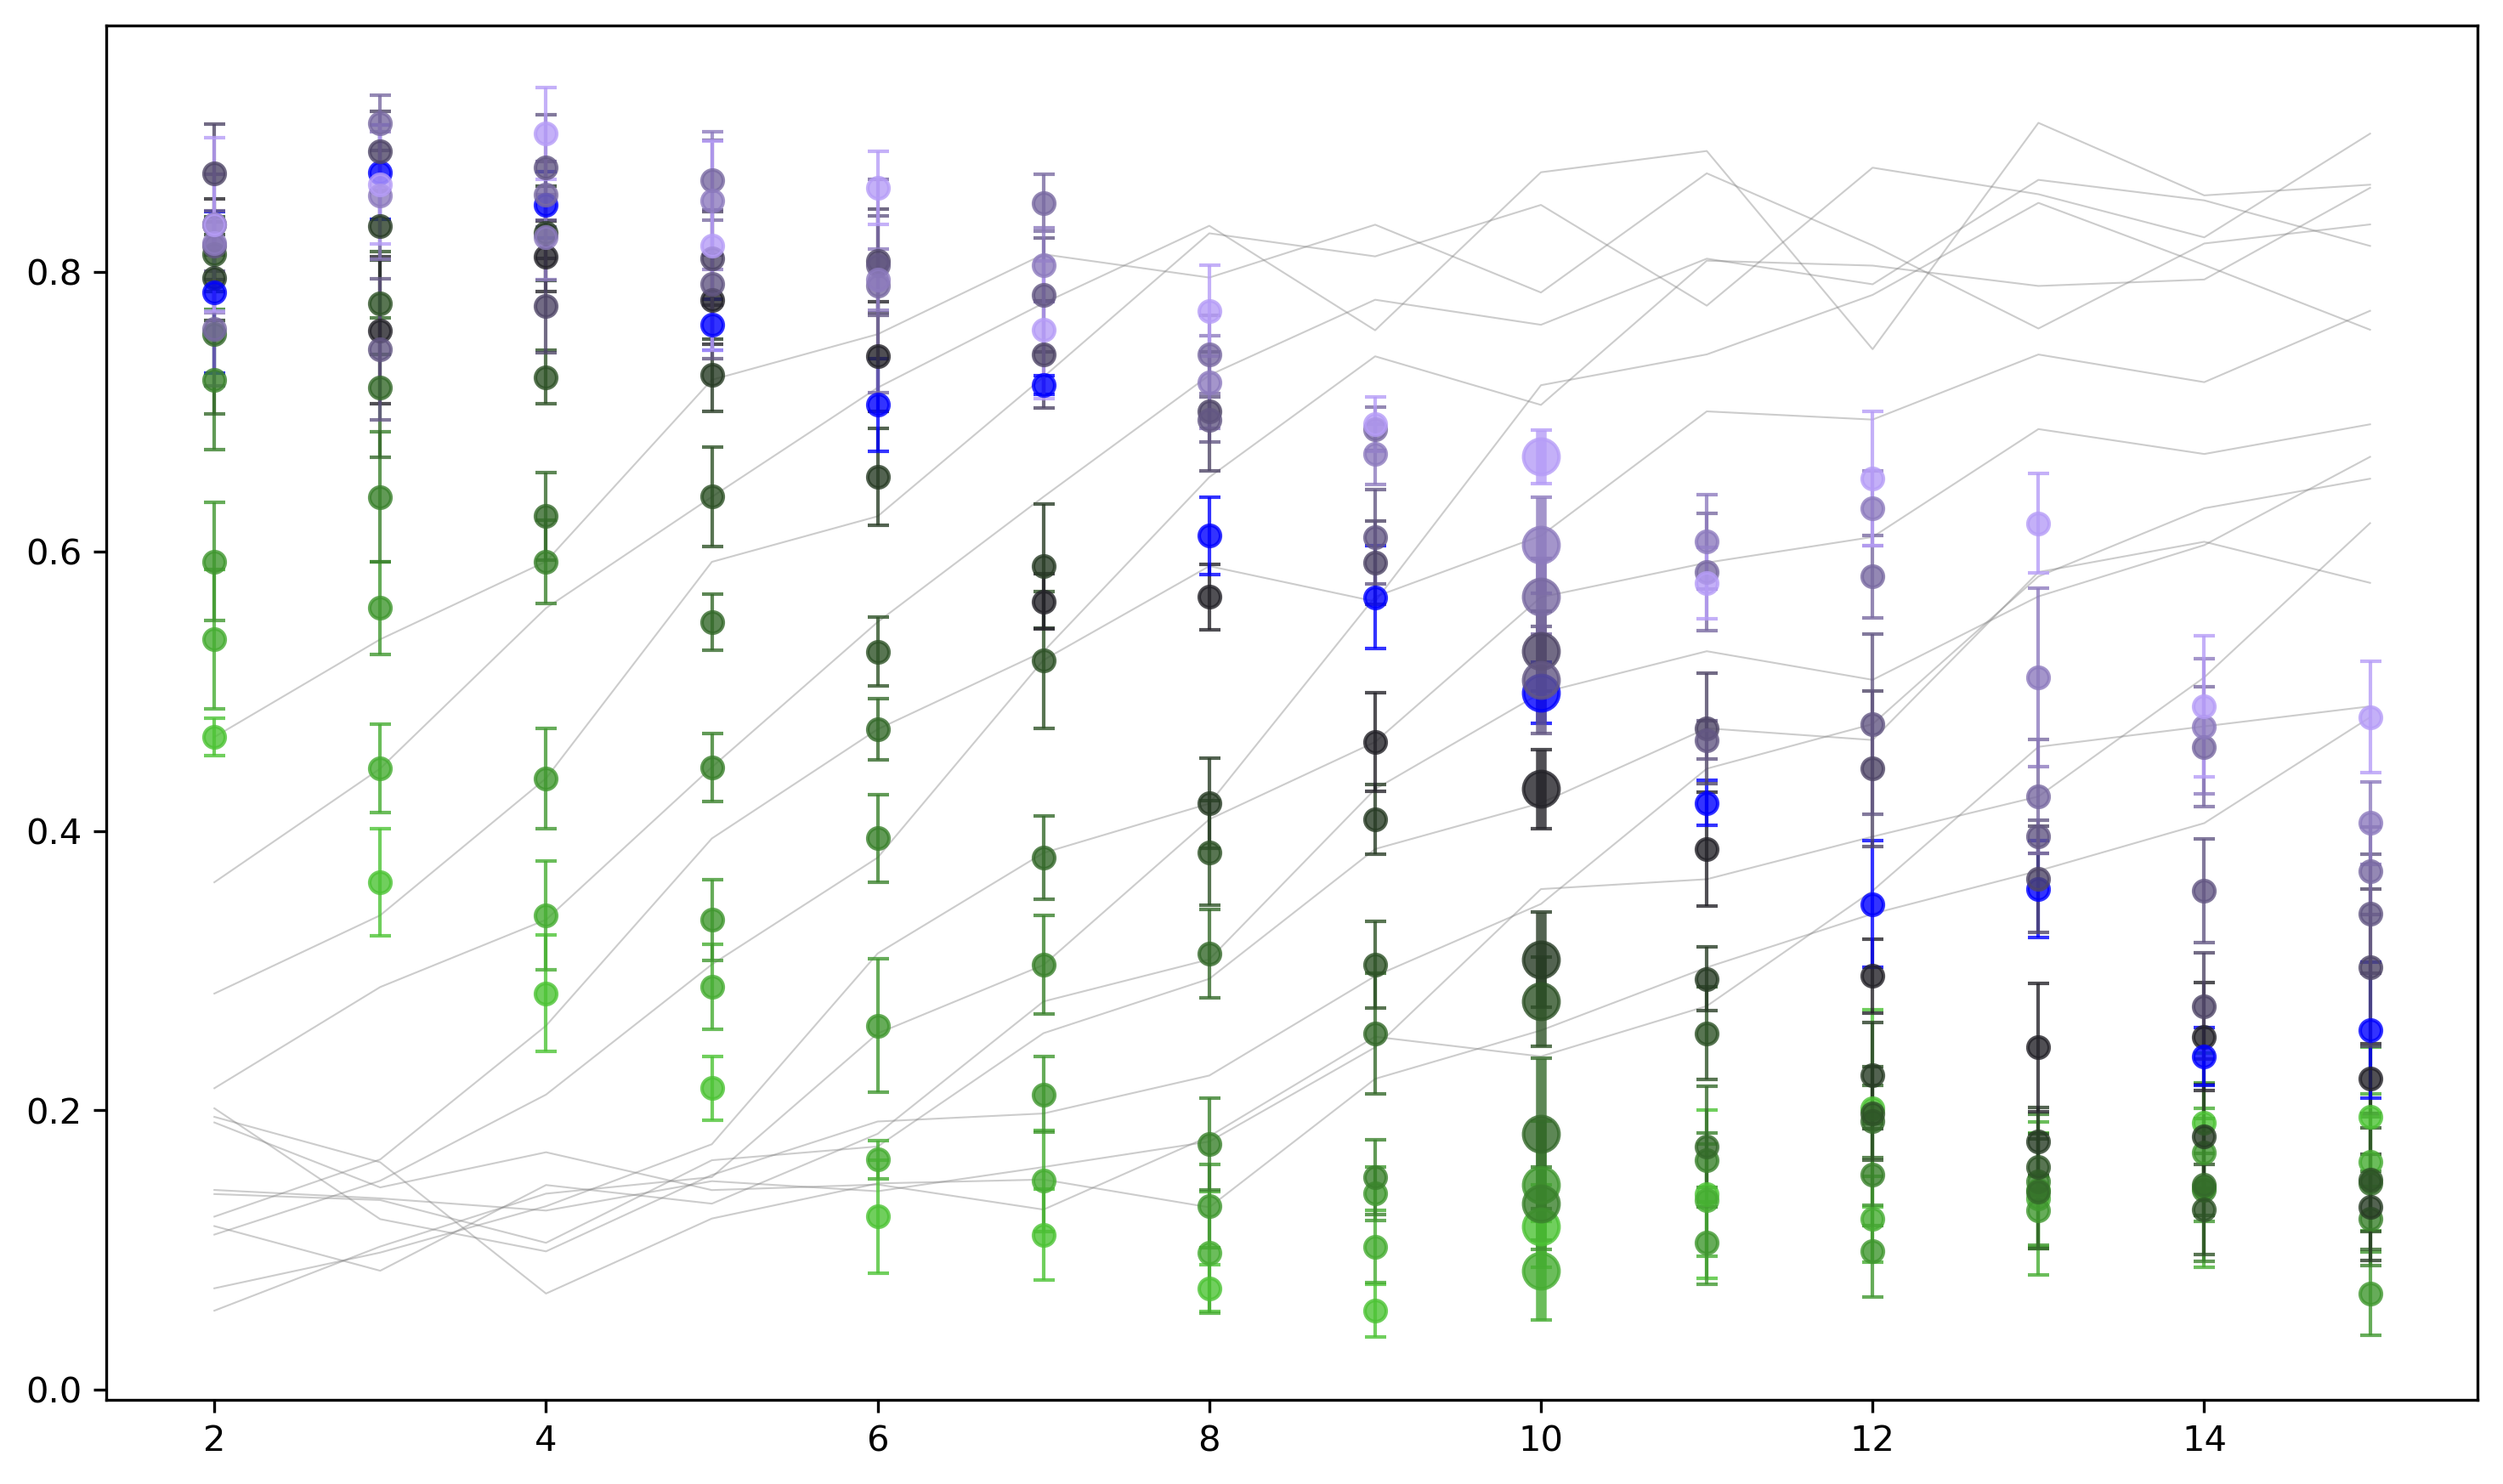

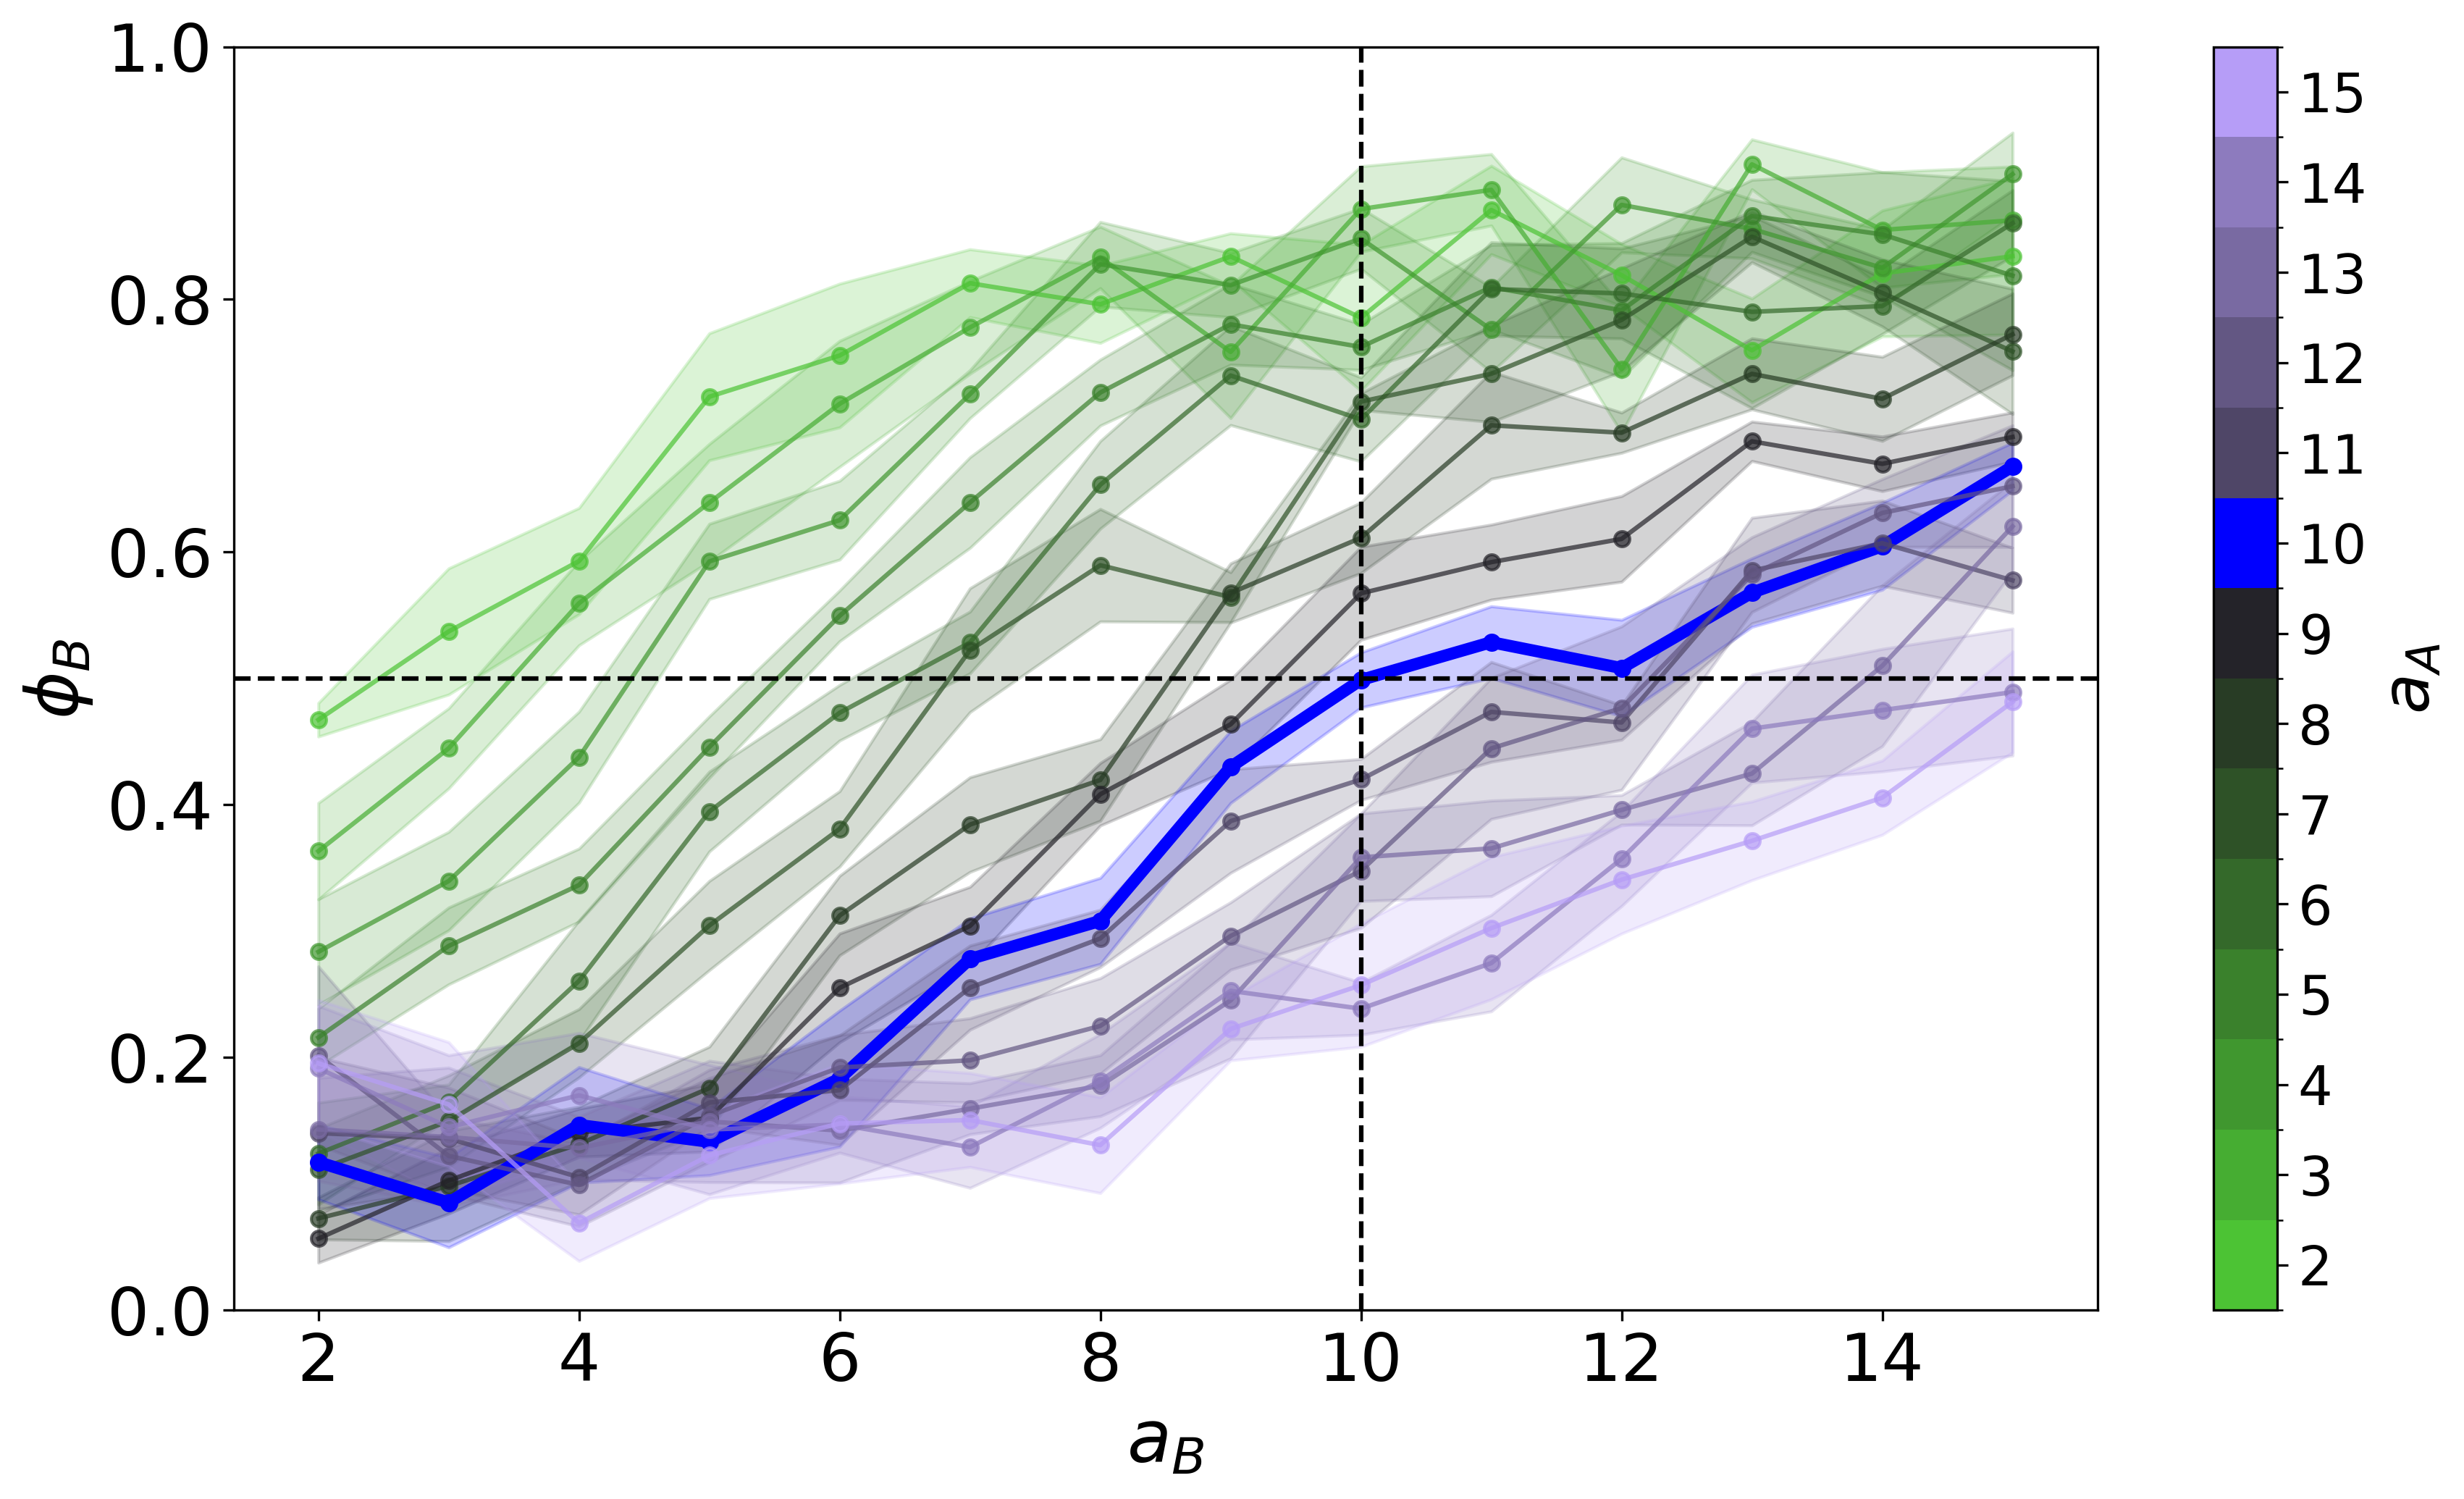

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable

df = pd.read_csv("/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/investigations/MAR26_all_aspects_periphery_fractions.csv")


df_third_to_last = df.groupby(['Aspect_Ratio_1', 'Aspect_Ratio_2']).nth(-8).reset_index()


asp_range = range(2, 16)
n = len(list(asp_range))
phi_B_matrix = np.full((n, n), np.nan)

for _, row in df_third_to_last.iterrows():
    a1 = int(row['Aspect_Ratio_1'])
    a2 = int(row['Aspect_Ratio_2'])
    if 2 <= a1 <= 15 and 2 <= a2 <= 15:
        phi_A = row['Avg_Fraction_Asp1']
        phi_B_matrix[a1 - 2, a2 - 2] = phi_A
        # symmetric
        phi_B_matrix[a2 - 2, a1 - 2] = 1 - phi_A

fig_hm, ax_hm = plt.subplots(figsize=(10, 8), dpi=300)
from scipy.ndimage import gaussian_filter

sns.heatmap(phi_B_matrix.T, annot=False, cmap='viridis',
            xticklabels=list(asp_range), yticklabels=list(asp_range),
            vmin=0, vmax=1, ax=ax_hm)
ax_hm.invert_yaxis()

#contour
Z_smooth = gaussian_filter(phi_B_matrix, sigma=1.5)
x_coords = np.arange(n) + 0.5   
y_coords = np.arange(n) + 0.5
ax_hm.contour(x_coords, y_coords, Z_smooth,
              levels=[0.25, 0.5, 0.75], colors='white', linewidths=2.5)

ax_hm.set_xlabel("$a_A$", fontsize=24)
ax_hm.set_ylabel("$a_B$", fontsize=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20, rotation=0)
cbar_hm = ax_hm.collections[0].colorbar
cbar_hm.ax.tick_params(labelsize=20)
cbar_hm.set_label(r"$\phi_A$", fontsize=24)
plt.tight_layout()
plt.savefig('phi_B_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


grouped_all = df_third_to_last.groupby(['Aspect_Ratio_1', 'Aspect_Ratio_2']).agg(
    avg_phi_B=('Avg_Fraction_Asp1', lambda x: 1 - np.mean(x)),
    sem_phi_B=('SEM_Avg_Fraction_Asp1', lambda x: np.sqrt(np.sum(x**2)) / len(x))
).reset_index()


colors = sns.diverging_palette(125, 275, s=90, l=70, n=15, center="dark").as_hex()
colors[8] = "#0000FF"
color_map = ListedColormap(colors)
bounds = np.arange(2, 17, 1)
cmap_norm = BoundaryNorm(bounds, color_map.N)
sm = ScalarMappable(cmap=color_map, norm=cmap_norm)
sm.set_array([])

fig_line, ax_line = plt.subplots(figsize=(12, 7), dpi=300)

for a1 in range(2, 16):
    subset = grouped_all[grouped_all['Aspect_Ratio_1'] == a1].sort_values('Aspect_Ratio_2')
    if subset.empty:
        continue
    for _, row in subset.iterrows():
        a2 = int(row['Aspect_Ratio_2'])
        color = color_map(cmap_norm(a2))
        lw = 3 if a1 == 10 else 1
        ax_line.errorbar(a1, row['avg_phi_B'], yerr=row['sem_phi_B'],
                         fmt='o', color=color, ecolor=color,
                         capsize=3, markersize=6 if a1 != 10 else 10,
                         linewidth=lw, alpha=0.8)

    
    ax_line.plot(subset['Aspect_Ratio_2'], subset['avg_phi_B'],
                 color='gray', linewidth=0.5, alpha=0.4, zorder=0)

fig_line2, ax_line2 = plt.subplots(figsize=(12, 7), dpi=300)

for a1 in range(2, 16):
    subset = grouped_all[grouped_all['Aspect_Ratio_1'] == a1].sort_values('Aspect_Ratio_2')
    if subset.empty:
        continue
    a2_vals = subset['Aspect_Ratio_2'].values
    phi_vals = subset['avg_phi_B'].values
    sem_vals = subset['sem_phi_B'].values

    lw = 4 if a1 == 10 else 1.5
    alpha = 1.0 if a1 == 10 else 0.7
    color = color_map(cmap_norm(a1))

    ax_line2.plot(a2_vals, phi_vals, '-o', color=color, linewidth=lw,
                  markersize=5, alpha=alpha)
    ax_line2.fill_between(a2_vals, phi_vals - sem_vals, phi_vals + sem_vals,
                          color=color, alpha=0.2)

ax_line2.axhline(0.5, color='black', linestyle='--', linewidth=1.5)
ax_line2.axvline(10, color='black', linestyle='--', linewidth=1.5)
ax_line2.set_xlabel("$a_B$", fontsize=24)
ax_line2.set_ylabel(r"$\phi_B$", fontsize=24)
ax_line2.set_ylim(0, 1.0)
ax_line2.tick_params(axis='both', labelsize=22)

sm2 = ScalarMappable(cmap=color_map, norm=cmap_norm)
sm2.set_array([])
cbar2 = fig_line2.colorbar(sm2, ax=ax_line2, orientation='vertical',
                            boundaries=bounds, ticks=bounds + 0.5)
cbar2.set_label('$a_A$', fontsize=22)
cbar2.ax.set_yticklabels([str(int(i)) for i in bounds])
cbar2.ax.tick_params(labelsize=18)

plt.tight_layout()
plt.savefig('phi_B_vs_aB_all_aspects.png', dpi=300, bbox_inches='tight')
plt.show()

## Different Periphery Criteria

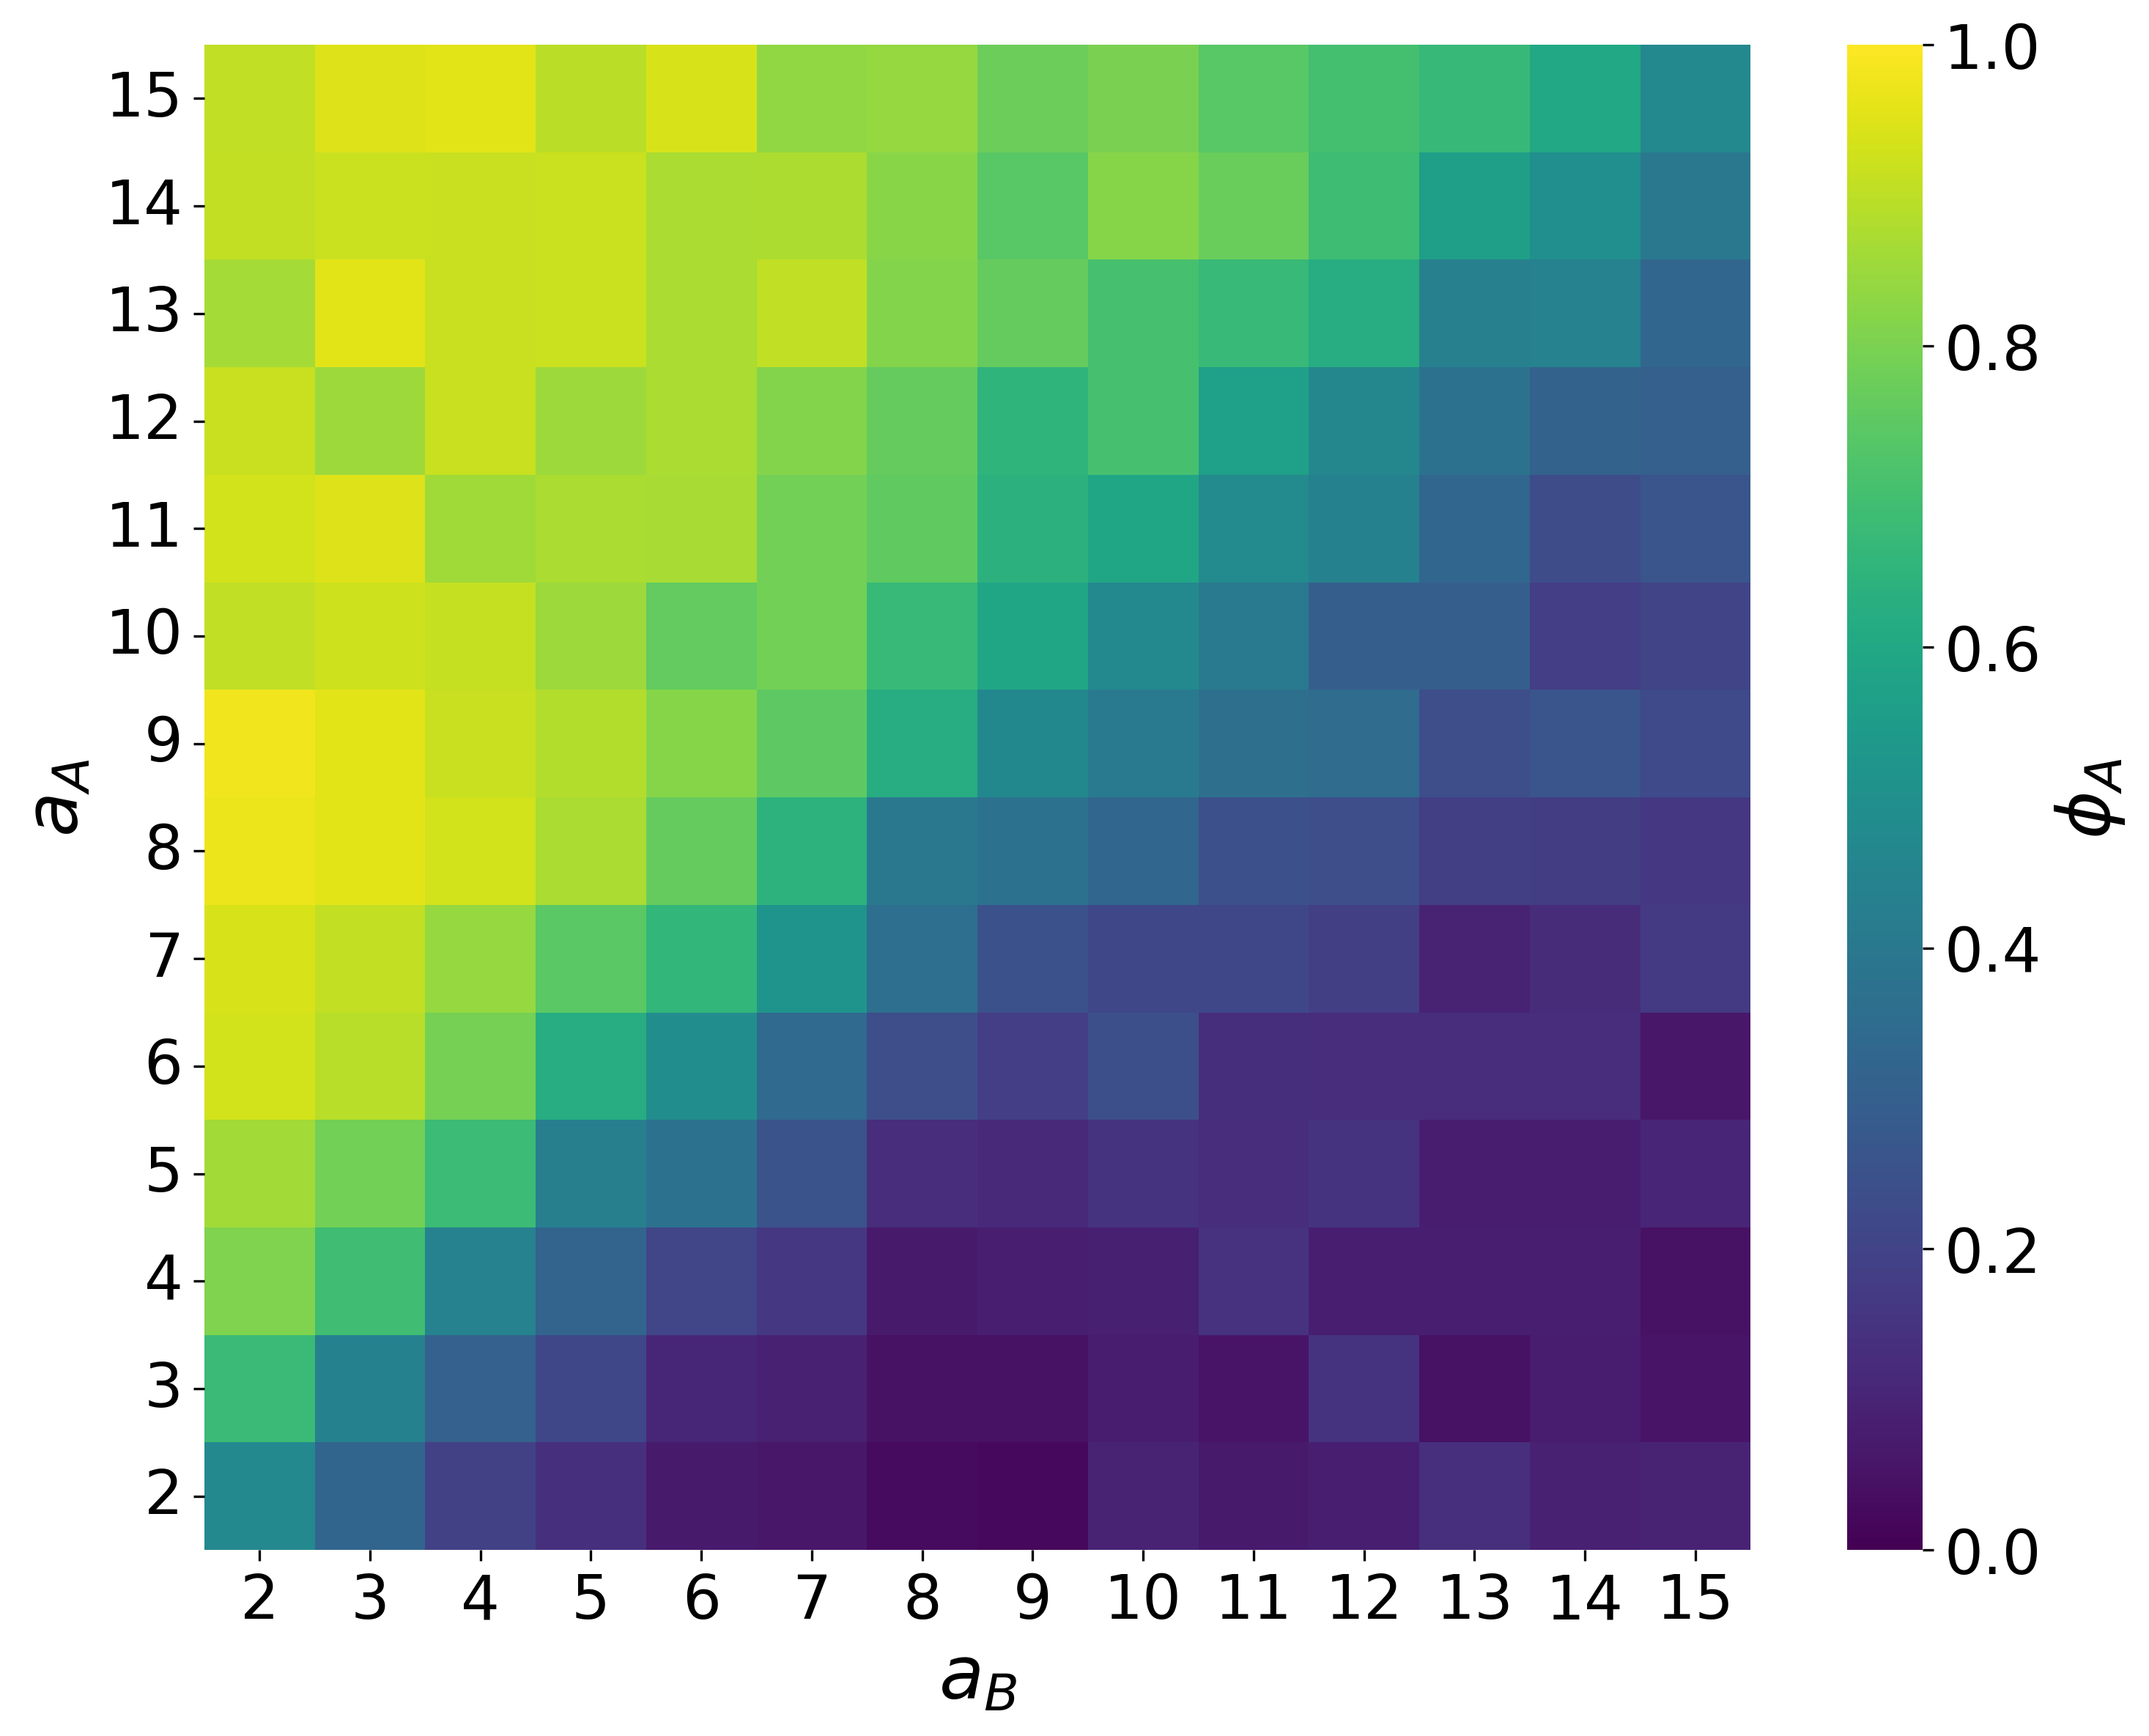

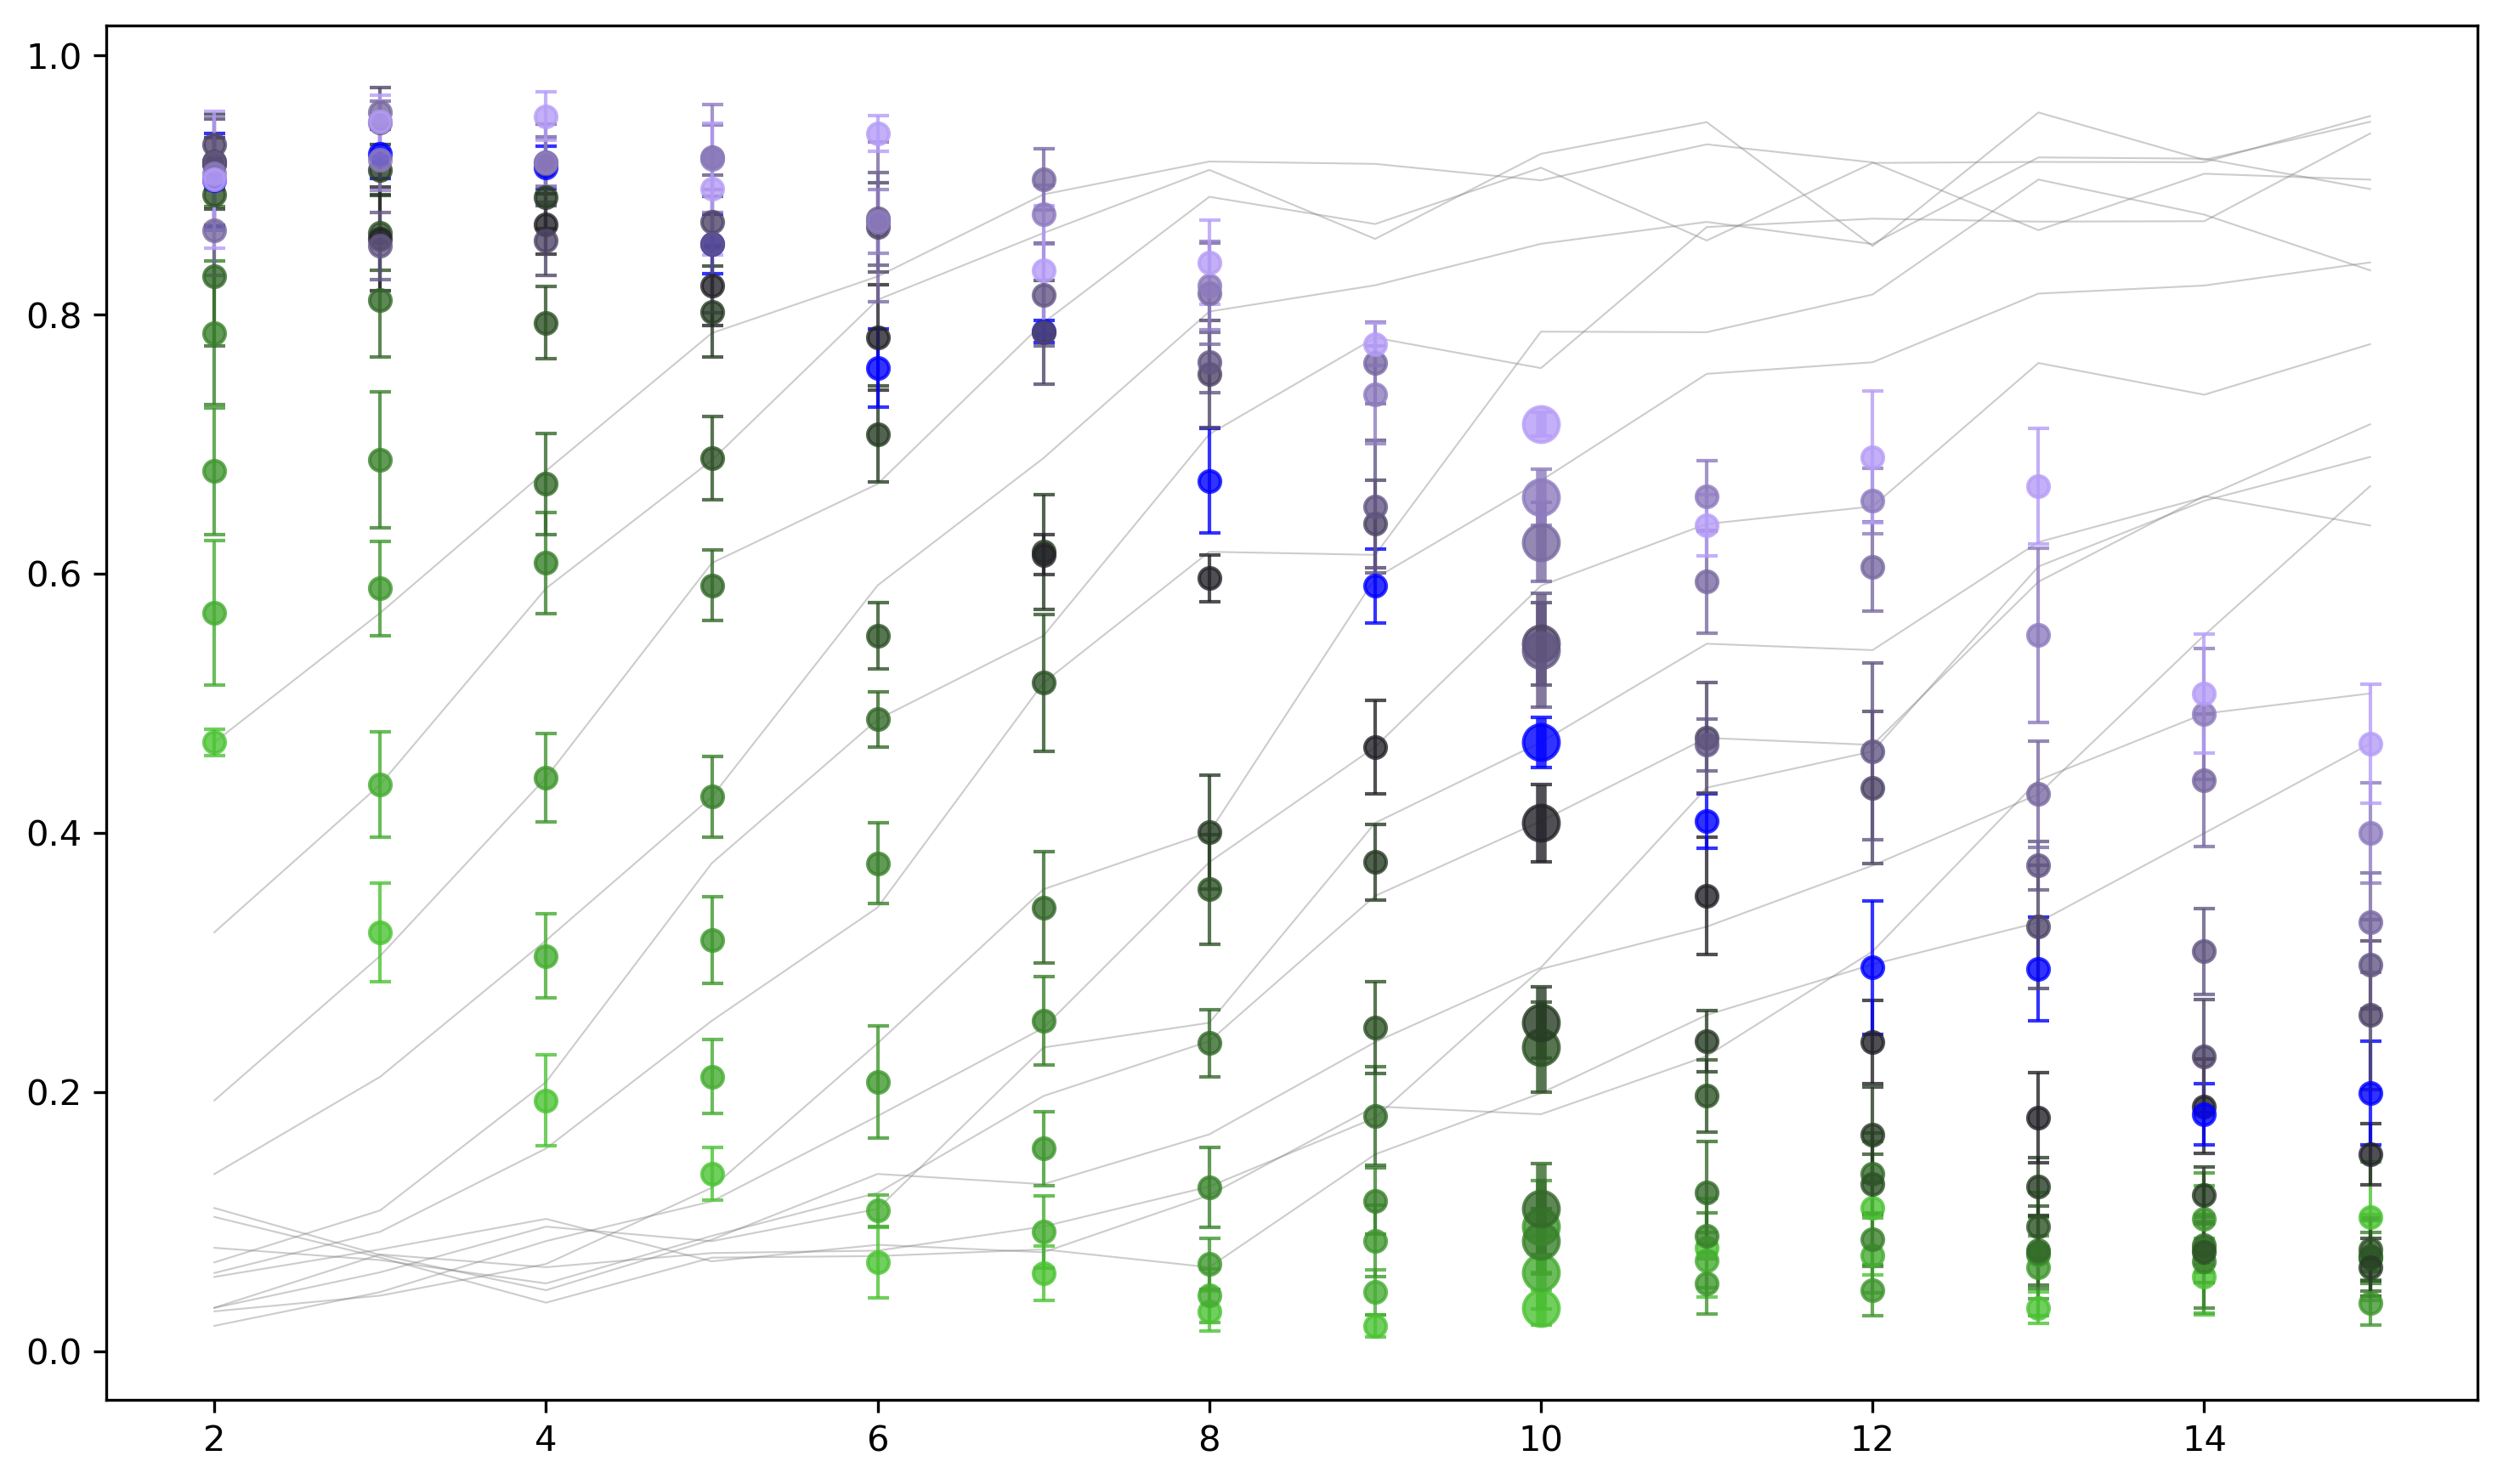

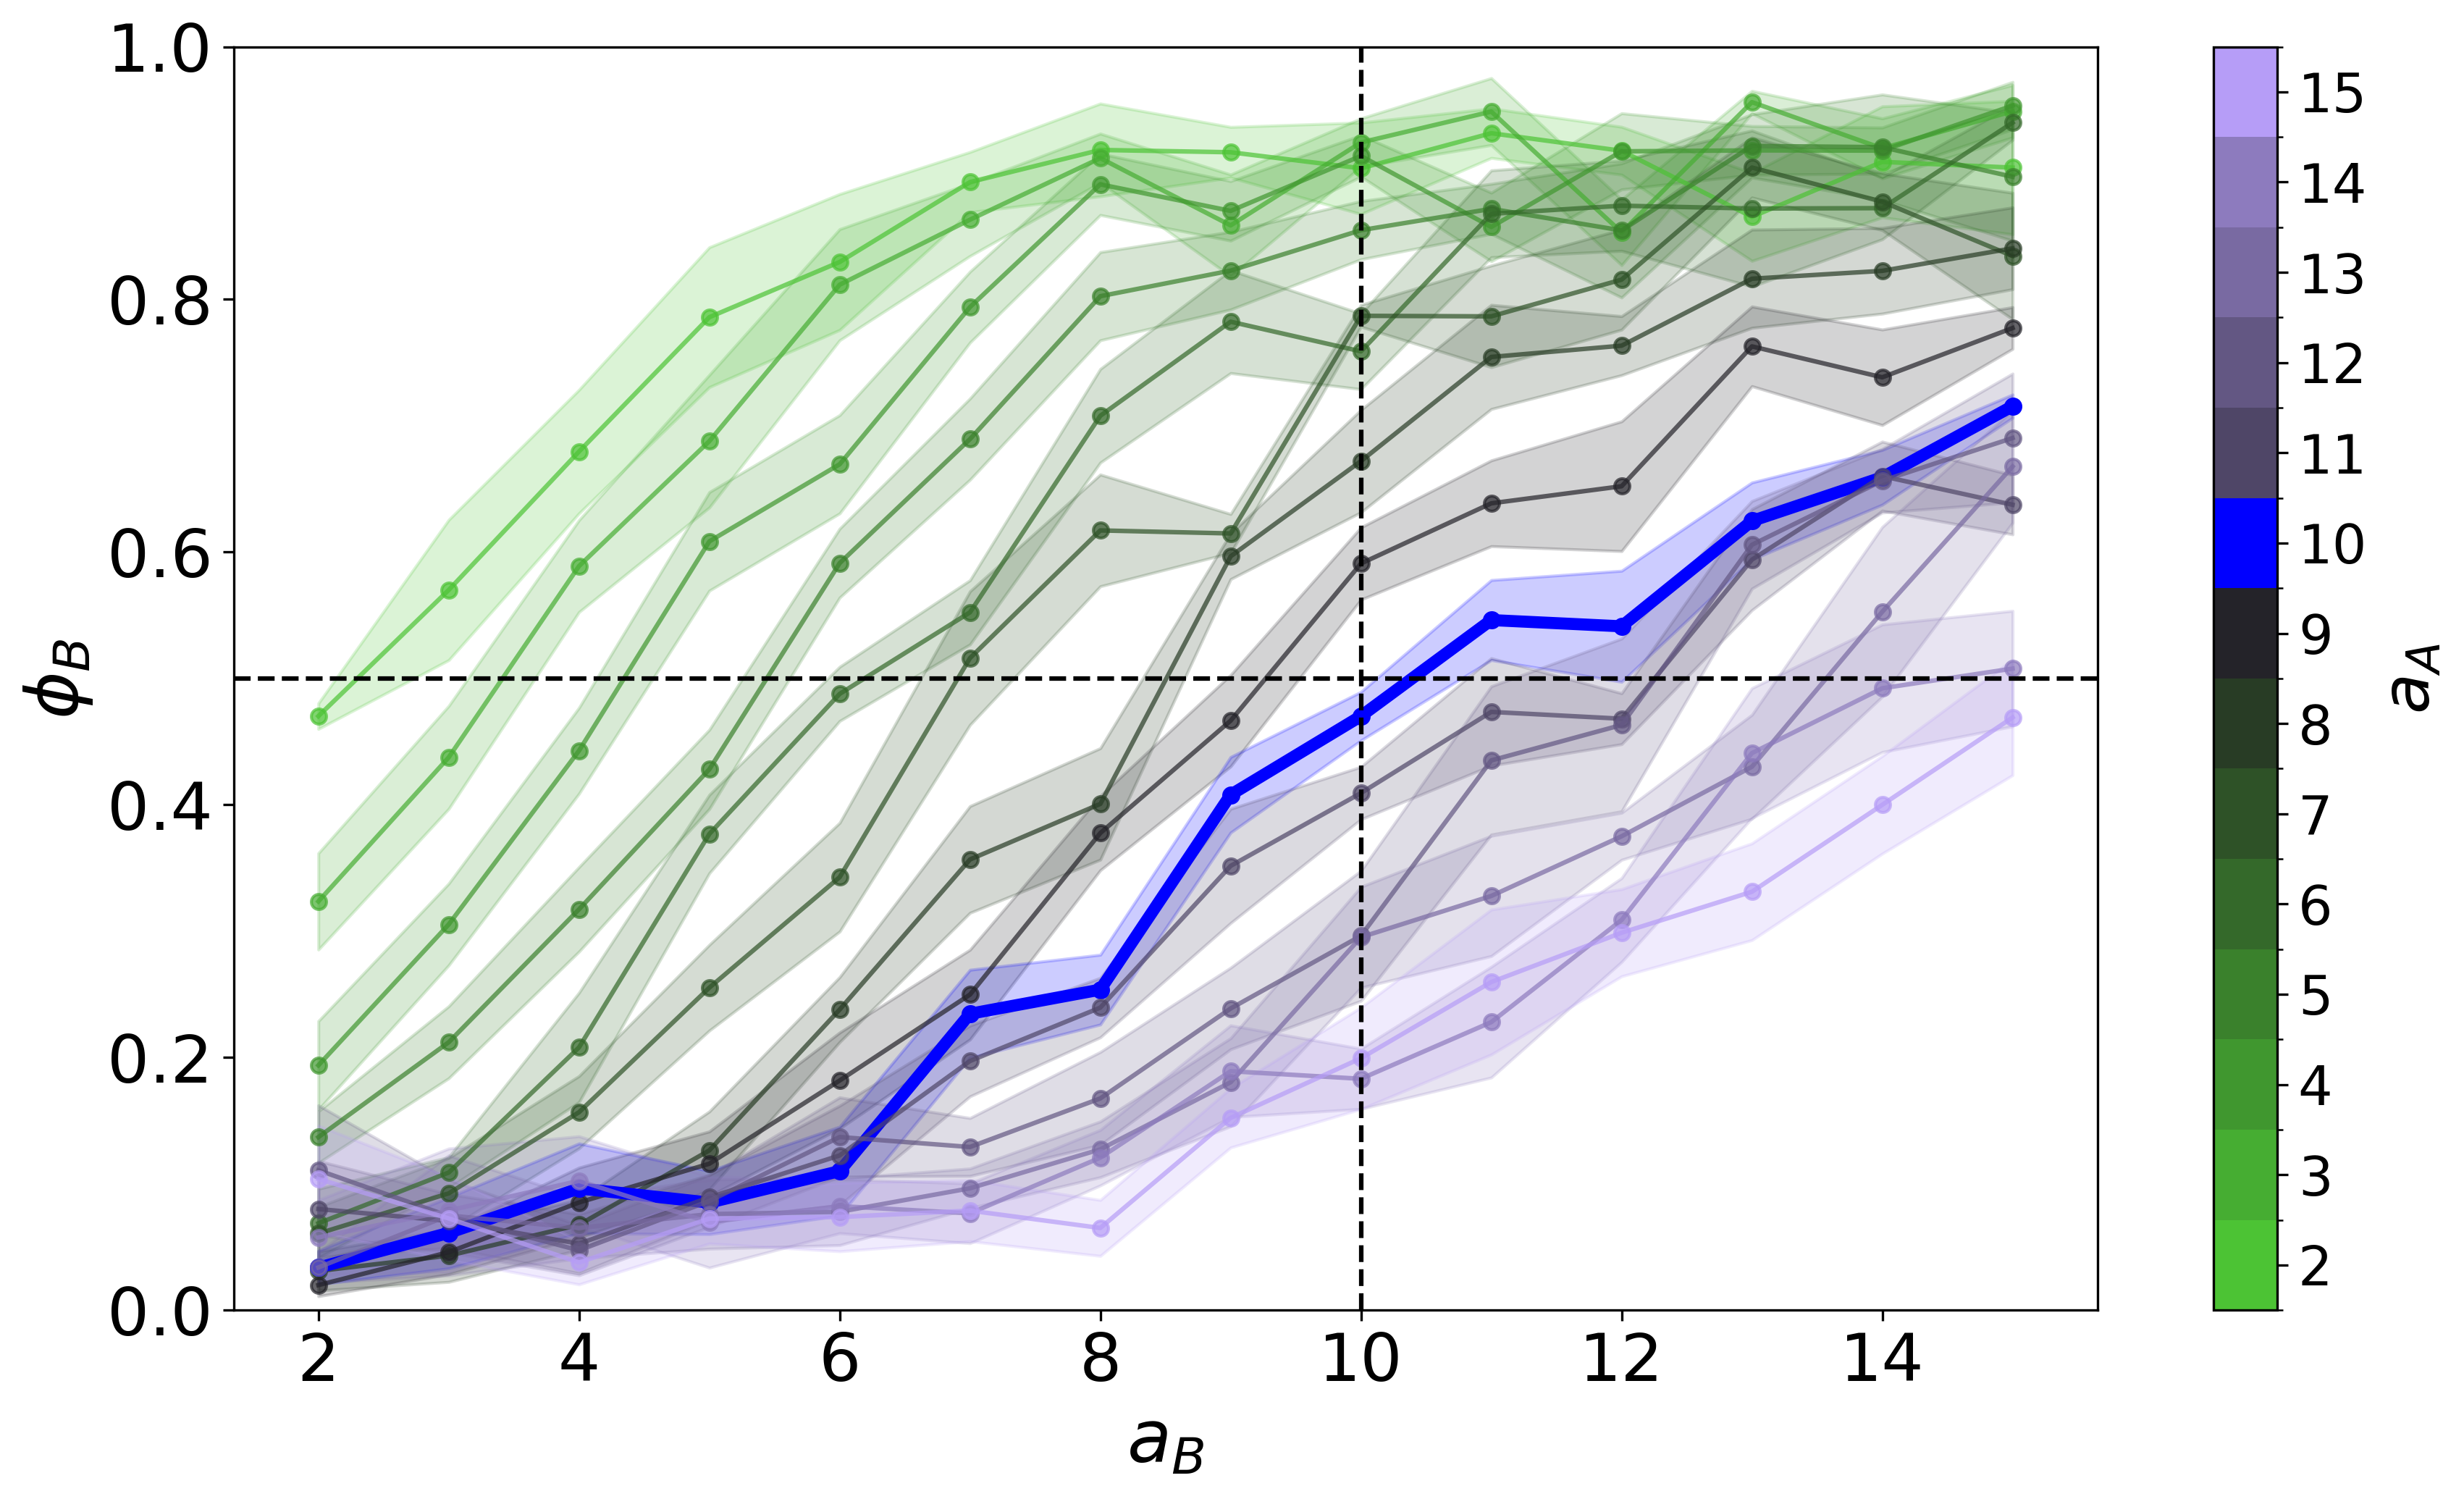

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.colors as mcolors
from scipy.optimize import curve_fit
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable

df = pd.read_csv("/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/investigations/MAR26_all_aspects_periphery_fractions_w=1d.csv")

df_third_to_last = df.groupby(['Aspect_Ratio_1', 'Aspect_Ratio_2']).nth(-8).reset_index()


asp_range = range(2, 16)
n = len(list(asp_range))
phi_B_matrix = np.full((n, n), np.nan)

for _, row in df_third_to_last.iterrows():
    a1 = int(row['Aspect_Ratio_1'])
    a2 = int(row['Aspect_Ratio_2'])
    if 2 <= a1 <= 15 and 2 <= a2 <= 15:
        phi_A = row['Avg_Fraction_Asp1']
        phi_B_matrix[a1 - 2, a2 - 2] = phi_A
        
        phi_B_matrix[a2 - 2, a1 - 2] = 1 - phi_A

fig_hm, ax_hm = plt.subplots(figsize=(10, 8), dpi=300)
sns.heatmap(phi_B_matrix, annot=False, cmap='viridis',
            xticklabels=list(asp_range), yticklabels=list(asp_range),
            vmin=0, vmax=1, ax=ax_hm)
ax_hm.invert_yaxis()
ax_hm.set_xlabel("$a_B$", fontsize=24)
ax_hm.set_ylabel("$a_A$", fontsize=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20, rotation=0)
cbar_hm = ax_hm.collections[0].colorbar
cbar_hm.ax.tick_params(labelsize=20)
cbar_hm.set_label(r"$\phi_A$", fontsize=24)
plt.tight_layout()
plt.savefig('phi_B_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


grouped_all = df_third_to_last.groupby(['Aspect_Ratio_1', 'Aspect_Ratio_2']).agg(
    avg_phi_B=('Avg_Fraction_Asp1', lambda x: 1 - np.mean(x)),
    sem_phi_B=('SEM_Avg_Fraction_Asp1', lambda x: np.sqrt(np.sum(x**2)) / len(x))
).reset_index()


colors = sns.diverging_palette(125, 275, s=90, l=70, n=15, center="dark").as_hex()
colors[8] = "#0000FF"
color_map = ListedColormap(colors)
bounds = np.arange(2, 17, 1)
cmap_norm = BoundaryNorm(bounds, color_map.N)
sm = ScalarMappable(cmap=color_map, norm=cmap_norm)
sm.set_array([])

fig_line, ax_line = plt.subplots(figsize=(12, 7), dpi=300)

for a1 in range(2, 16):
    subset = grouped_all[grouped_all['Aspect_Ratio_1'] == a1].sort_values('Aspect_Ratio_2')
    if subset.empty:
        continue
    for _, row in subset.iterrows():
        a2 = int(row['Aspect_Ratio_2'])
        color = color_map(cmap_norm(a2))
        lw = 3 if a1 == 10 else 1
        ax_line.errorbar(a1, row['avg_phi_B'], yerr=row['sem_phi_B'],
                         fmt='o', color=color, ecolor=color,
                         capsize=3, markersize=6 if a1 != 10 else 10,
                         linewidth=lw, alpha=0.8)

    
    ax_line.plot(subset['Aspect_Ratio_2'], subset['avg_phi_B'],
                 color='gray', linewidth=0.5, alpha=0.4, zorder=0)


fig_line2, ax_line2 = plt.subplots(figsize=(12, 7), dpi=300)

for a1 in range(2, 16):
    subset = grouped_all[grouped_all['Aspect_Ratio_1'] == a1].sort_values('Aspect_Ratio_2')
    if subset.empty:
        continue
    a2_vals = subset['Aspect_Ratio_2'].values
    phi_vals = subset['avg_phi_B'].values
    sem_vals = subset['sem_phi_B'].values

    lw = 4 if a1 == 10 else 1.5
    alpha = 1.0 if a1 == 10 else 0.7
    color = color_map(cmap_norm(a1))

    ax_line2.plot(a2_vals, phi_vals, '-o', color=color, linewidth=lw,
                  markersize=5, alpha=alpha)
    ax_line2.fill_between(a2_vals, phi_vals - sem_vals, phi_vals + sem_vals,
                          color=color, alpha=0.2)

ax_line2.axhline(0.5, color='black', linestyle='--', linewidth=1.5)
ax_line2.axvline(10, color='black', linestyle='--', linewidth=1.5)
ax_line2.set_xlabel("$a_B$", fontsize=24)
ax_line2.set_ylabel(r"$\phi_B$", fontsize=24)
ax_line2.set_ylim(0, 1.0)
ax_line2.tick_params(axis='both', labelsize=22)


sm2 = ScalarMappable(cmap=color_map, norm=cmap_norm)
sm2.set_array([])
cbar2 = fig_line2.colorbar(sm2, ax=ax_line2, orientation='vertical',
                            boundaries=bounds, ticks=bounds + 0.5)
cbar2.set_label('$a_A$', fontsize=22)
cbar2.ax.set_yticklabels([str(int(i)) for i in bounds])
cbar2.ax.tick_params(labelsize=18)

plt.tight_layout()
plt.savefig('phi_B_vs_aB_all_aspects.png', dpi=300, bbox_inches='tight')
plt.show()

## Visualization

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.cm import get_cmap
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import alphashape
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Polygon as MplPolygon


brown_rgb = (89/255, 168/255, 217/255)   
light_blue_rgb = (127/255, 73/255, 23/255)  
brown_to_light_blue_cb_friendly = LinearSegmentedColormap.from_list(
    "brown_lightblue_cb", [light_blue_rgb, brown_rgb]
)


class Measurements:
    def __init__(self, dataPath: str, time: int):
        opts = pd.read_csv(f"{dataPath}/opts.csv", header=0).to_dict(orient="index")[0]
        df = pd.read_csv(f"{dataPath}/{time}.csv", header=0)

        
        if "gadj" not in df.columns:
            df["gadj"] = 0.0
        if "stale" not in df.columns:
            df["stale"] = 0.0

        keys = ["x","y","ex","ey","l","color","color2",
                "fx","fy","g","splits","id_1","id_2",
                "ancestors","ancestor","gadj","stale"]
        for key in keys:
            setattr(self, key, df[key].values if key in df.columns else np.zeros(len(df)))

        self.phi = np.arctan2(self.ey, self.ex) + np.pi

        opts_keys = ["time_step","thickness",
                     "division_length_1","division_length_2",
                     "diffusion_constant","force_constant",
                     "initial_type","growth_rate_1","growth_rate_2",
                     "rng_seed","initial_cells","system_size"]
        legacy = {
            "division_length_1":"division_lengths_1",
            "division_length_2":"division_lengths_2",
            "growth_rate_1":"growth_rates_1",
            "growth_rate_2":"growth_rates_2",
        }
        for key in opts_keys:
            if key in opts:
                setattr(self, key, opts[key])
            elif key in legacy and legacy[key] in opts:
                setattr(self, key, opts[legacy[key]])

        self.max_aspect_ratio_1 = self.division_length_1 / self.thickness
        self.max_aspect_ratio_2 = self.division_length_2 / self.thickness
        self.r = self.thickness / 2.0
        self.local_radius = (3/16)*(self.division_length_1 + self.division_length_2)
        self.time = df["time"].values[0] if "time" in df else time*self.time_step

    def set_local_radius(self, radius: float):
        self.local_radius = radius


def colorSelector(colorby, data):
    vrange = np.array([0, 1])
    if colorby == "length":
        lengths = np.array([data.division_length_1, data.division_length_2])
        vrange = [lengths.min()/2, lengths.max()]
        values = (data.l - data.l.min())/(data.l.max() - data.l.min())
        cm = get_cmap("coolwarm")
    elif colorby == "allele":
        allele = data.color
        vrange = [allele.min(), allele.max()]
        values = allele / allele.max()
        cm = get_cmap("hsv")
    elif colorby == "uptake":
        uptake = data.gadj
        vrange = [uptake.min(), uptake.max()]
        values = uptake / uptake.max()
        cm = get_cmap("inferno")
    elif colorby == "stale":
        values = 1.0 - data.stale.astype(float)
        vrange = [0.0, 1.0]
        cm = get_cmap("gnuplot")
    else:
        values = data.color2.astype(float)
        cm = brown_to_light_blue_cb_friendly
    return cm, values, vrange


def iterateRods(ax, coloring, x, y, ex, ey, l, phi, R, resp=0.01):
    r = R - resp
    for i in range(len(x)):
        color = coloring[i]
        x1, y1 = x[i] - (0.5*l[i]-r)*ex[i], y[i] - (0.5*l[i]-r)*ey[i]
        x2, y2 = x[i] + (0.5*l[i]-r)*ex[i], y[i] + (0.5*l[i]-r)*ey[i]
        angle = np.arctan2(ey[i], ex[i])
        epx, epy = -np.sin(angle), np.cos(angle)
        c1 = Circle((x1,y1), r, color=color)
        c2 = Circle((x2,y2), r, color=color)
        xr, yr = x1 - epx*r, y1 - epy*r
        rect = Rectangle((xr, yr), width=l[i]-2*r, height=2*r, angle=np.degrees(angle), color=color)
        for artist in [c2, rect, c1]:
            ax.add_artist(artist)


def shapely_to_patches(geom):
    patches = []
    if geom.is_empty:
        return patches
    if geom.geom_type == "Polygon":
        patches.append(MplPolygon(list(geom.exterior.coords), closed=True))
    elif geom.geom_type == "MultiPolygon":
        for poly in geom.geoms:
            patches.append(MplPolygon(list(poly.exterior.coords), closed=True))
    elif geom.geom_type == "GeometryCollection":
        for g in geom.geoms:
            patches.extend(shapely_to_patches(g))
    else:
        patches.append(MplPolygon(list(geom.buffer(0.001).exterior.coords), closed=True))
    return patches


from shapely.geometry import Point, Polygon, MultiPoint
from shapely.ops import unary_union
from scipy.spatial import KDTree

def drawRodsWithPeripheryAnnulus(time, datapath, imgPath="", saveImg=False,
                                     colorby="allele", alpha=1.1, distance_threshold=0.5,
                                     hull_outline_color="black", hull_outline_width=2.0,
                                     periphery_color="cyan", periphery_alpha=0.3,
                                     hidedecoration=False):
    data = Measurements(datapath, time)
    x, y, ex, ey, l, R, phi = data.x, data.y, data.ex, data.ey, data.l, data.r, data.phi
    cm, values, vrange = colorSelector(colorby, data)
    rod_colors = cm(values)

    
    fig, ax = plt.subplots(figsize=(10,10))
    ax.set_aspect("equal")
    tmax = max(max(abs(x)), max(abs(y))) + 2*data.thickness
    ax.set_xlim(-tmax -1, tmax + 1)
    ax.set_ylim(-tmax -1, tmax + 1)
    ax.tick_params(axis="both", labelsize=14)

    
    rod_endpoints = np.empty((2*len(x),2))
    orientations = np.arctan2(ey, ex)
    for i, (xi, yi, li, ori) in enumerate(zip(x, y, l, orientations)):
        dx, dy = 0.5*li*np.cos(ori), 0.5*li*np.sin(ori)
        rod_endpoints[2*i] = xi - dx, yi - dy
        rod_endpoints[2*i+1] = xi + dx, yi + dy

  
    hull = alphashape.alphashape(rod_endpoints, alpha)

    
    hull_patch = MplPolygon(np.array(hull.exterior.coords),
                            fill=False,
                            edgecolor=hull_outline_color,
                            linewidth=hull_outline_width,
                            zorder=15)
    ax.add_patch(hull_patch)


    hull_points = np.array(hull.exterior.coords)
    tree = KDTree(hull_points)


    r = R - 0.01
    for i in range(len(x)):
        color = rod_colors[i]
        x1, y1 = x[i] - (0.5*l[i]-r)*ex[i], y[i] - (0.5*l[i]-r)*ey[i]
        x2, y2 = x[i] + (0.5*l[i]-r)*ex[i], y[i] + (0.5*l[i]-r)*ey[i]

        angle = np.arctan2(ey[i], ex[i])
        epx, epy = -np.sin(angle), np.cos(angle)

        c1 = Circle((x1, y1), r, color=color)
        c2 = Circle((x2, y2), r, color=color)
        rect = Rectangle((x1 - epx*r, y1 - epy*r), width=l[i]-2*r, height=2*r,
                         angle=np.degrees(angle), color=color)

        dist1, _ = tree.query([x1, y1])
        dist2, _ = tree.query([x2, y2])
        if dist1 <= distance_threshold or dist2 <= distance_threshold:
            
            rect_periph = Rectangle((x1 - epx*r, y1 - epy*r), width=l[i]-2*r, height=2*r,
                                    angle=np.degrees(angle),
                                    color=periphery_color, alpha=periphery_alpha, zorder=10)
            ax.add_artist(rect_periph)

        for artist in [c2, rect, c1]:
            ax.add_artist(artist)


    norm = mpl.colors.Normalize(vmin=vrange[0], vmax=vrange[1])
    sm = mpl.cm.ScalarMappable(cmap=cm, norm=norm)
    divider = make_axes_locatable(ax)
    cbar_ax = divider.append_axes("right", size="3%", pad=0.1)
    cb = plt.colorbar(sm, cax=cbar_ax)
    cb.set_ticks([vrange[0], vrange[1]])
    cb.ax.tick_params(labelsize=12)

    if hidedecoration:
        ax.set_xticks([])
        ax.set_yticks([])

    ax.set_title(f"t = {time}", fontsize=16)
    ax.legend(loc="upper right", fontsize=10, framealpha=0.6)

    if saveImg and imgPath:
        plt.savefig(f"{imgPath}/{time}_periphery.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()

/var/folders/ny/b0jp1x690g9c3lxrbj_5p5nc0000gn/T/ipykernel_80640/3111901252.py:226: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right", fontsize=10, framealpha=0.6)


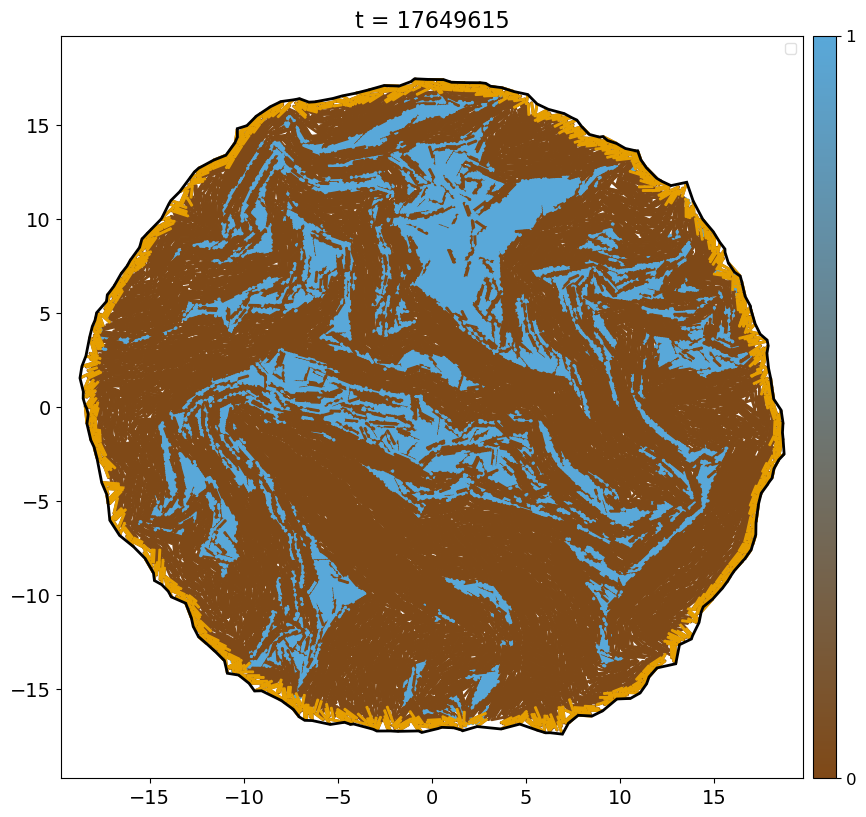

In [ ]:
drawRodsWithPeripheryAnnulus(
    time=17649615,
    datapath="/Volumes/T7/activeMatterCommunities/workspace/simulations_eqdivtime/asp10/run1/cycles:2100000000-max_ptcls:25000-frame_size:400000-system_size:150.0-time_step:0.005-thickness:0.1-diffusion_constant:0.0-force_constant:100.0-initial_type:uniform-division_lengths:1.0,0.2-growth_rates:5e-05,1e-05-initial_cells:50-rng_seed:1712031202",
    colorby="population",
    distance_threshold=0.5,        
    periphery_color="#E69F00",
    periphery_alpha=1.0,
)